In [12]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

Koneksi ke Google Drive

In [13]:
BASE_DIR = os.getcwd()

FITUR = ['Umur (bulan)', 'Tinggi Badan (cm)', 'Jenis Kelamin']
TARGET = 'Status Gizi'

df = pd.read_csv(
    os.path.join(BASE_DIR, "dataset_tinggi_balita.csv")
)

df.head()

,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
0,0,laki-laki,44.5,stunted
1,0,laki-laki,56.7,tinggi
2,0,laki-laki,46.8,normal
3,0,laki-laki,47.5,normal
4,0,laki-laki,42.7,severely stunted


**Pengkodean (mapping) jenis kelamin dan status gizi**

In [14]:
#transfrom value
df['Jenis Kelamin'] = df['Jenis Kelamin'].map({'laki-laki': 0, 'perempuan': 1})
df['Status Gizi'] = df['Status Gizi'].map({'severely stunted': 0, 'stunted': 1, 'normal': 2, 'tinggi': 3})

#remove NAN
df = df.dropna(subset=FITUR + [TARGET])
df

,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
0,0,0,44.5,1
1,0,0,56.7,3
2,0,0,46.8,2
3,0,0,47.5,2
4,0,0,42.7,0
...,...,...,...,...
120994,60,1,100.6,2
120995,60,1,98.3,1
120996,60,1,121.3,2
120997,60,1,112.2,2


In [15]:
#remove duplicate
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} after drop_duplicates")


X = df[FITUR]
y = df[TARGET]

df


Rows: 120999 -> 34921 after drop_duplicates


,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
0,0,0,44.5,1
1,0,0,56.7,3
2,0,0,46.8,2
3,0,0,47.5,2
4,0,0,42.7,0
...,...,...,...,...
34916,60,1,100.7,2
34917,60,1,113.7,2
34918,60,1,107.5,2
34919,60,1,127.6,3


In [16]:
#split training data and testing data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X

,Umur (bulan),Tinggi Badan (cm),Jenis Kelamin
0,0,44.5,0
1,0,56.7,0
2,0,46.8,0
3,0,47.5,0
4,0,42.7,0
...,...,...,...
34916,60,100.7,1
34917,60,113.7,1
34918,60,107.5,1
34919,60,127.6,1


In [17]:

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma='scale')),
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, cv=skf, scoring='accuracy')
for i, s in enumerate(scores, 1):
    print(f"Fold {i} Accuracy: {s*100:.2f}%")
print(f"Mean CV Accuracy: {scores.mean()*100:.2f}%")

Fold 1 Accuracy: 98.57%
Fold 2 Accuracy: 98.75%
Fold 3 Accuracy: 98.48%
Fold 4 Accuracy: 98.89%
Fold 5 Accuracy: 98.19%
Mean CV Accuracy: 98.58%


                  precision    recall  f1-score   support

severely stunted       0.98      0.99      0.99      1101
         stunted       0.97      0.96      0.97       794
          normal       0.99      0.99      0.99      3952
          tinggi       0.99      0.99      0.99      1138

        accuracy                           0.99      6985
       macro avg       0.98      0.98      0.98      6985
    weighted avg       0.99      0.99      0.99      6985

Akurasi test: 98.83%


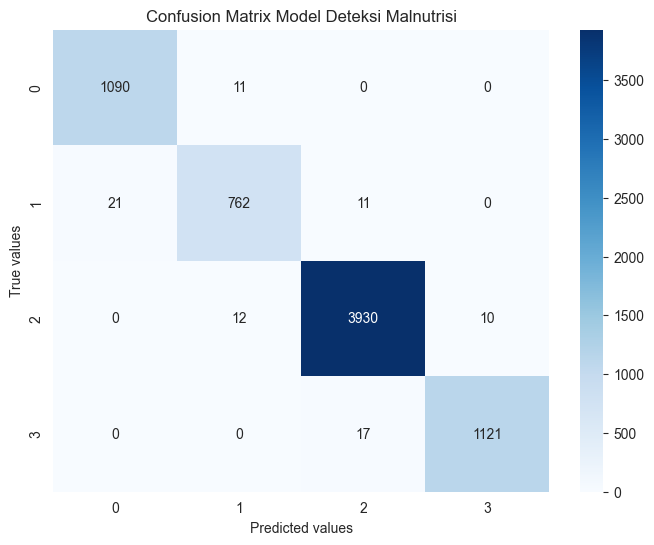

In [18]:
# 5. Fit final di seluruh data train, evaluasi di data test
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3],
    target_names=['severely stunted', 'stunted', 'normal', 'tinggi'],
    zero_division=0))
print(f"Akurasi test: {accuracy_score(y_test, y_pred)*100:.2f}%")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted values')
plt.ylabel('True values')
plt.title('Confusion Matrix Model Deteksi Malnutrisi')
plt.savefig(os.path.join(BASE_DIR, "confusion_matrix.png"), dpi=150, bbox_inches='tight')
plt.show()

In [19]:
model_path =   os.path.join(BASE_DIR, "stunted.pkl")

joblib.dump(pipeline, model_path)

['/Users/macbook/Downloads/posyandu-ai/stunted.pkl']

In [20]:



#try dump model
model_path = os.path.join(BASE_DIR, "stunted.pkl")
test_model = joblib.load(model_path)

test_model_stunting = pd.DataFrame({
    'Umur (bulan)': [45],
    'Jenis Kelamin': [0],   # 0 = laki-laki, 1 = perempuan
    'Tinggi Badan (cm)': [130],
})[FITUR]

y_pred_train = test_model.predict(X_train)
y_pred_test = test_model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

pred = test_model.predict(test_model_stunting)
print("Predicted Score = {}".format(np.array(pred)))




Training Accuracy: 0.9875071592210768
Test Accuracy: 0.9882605583392985
Predicted Score = [3]
